# Learning from Imbalanced Data

Many real classification problems have far more negatives than positives: fraud, disease screening,
equipment failure, click-through, and rare-event detection. A model can reach 99% accuracy by
predicting the majority class every time, while being useless.

This notebook covers:

- why accuracy is misleading under imbalance,
- class weights,
- random over-sampling, random under-sampling, and SMOTE,
- threshold tuning,
- precision-recall curves and PR-AUC.

## Learning objectives

1. Measure imbalance and explain the accuracy paradox.
2. Apply class weighting and resampling correctly inside a pipeline.
3. Use SMOTE and understand its limitations.
4. Choose a decision threshold based on precision/recall trade-offs.
5. Evaluate imbalanced classifiers with PR-AUC, F1, and recall.

## 1. Concepts

### Why imbalance is hard

If 98% of samples are negative, a constant-negative classifier has 98% accuracy and zero recall.
The loss function is dominated by the majority class, so the model may ignore the minority class.

### Approaches

1. **Class weights** - increase the loss for minority errors. Simple and usually a strong baseline.
2. **Random over-sampling** - duplicate minority samples; risks overfitting.
3. **Random under-sampling** - discard majority samples; loses information.
4. **SMOTE** - create synthetic minority samples by interpolating between nearest minority neighbours.
5. **Threshold tuning** - keep the model but choose a probability threshold that matches the cost of errors.
6. **Cost-sensitive learning** - encode the real costs directly in the objective when the library supports it.

### Evaluation

- Accuracy is misleading.
- **Recall** matters when missing a positive is expensive.
- **Precision** matters when false alarms are expensive.
- **F1** balances both.
- **PR-AUC** summarises the precision-recall trade-off and is usually more informative than ROC-AUC
  when positives are rare.

## 2. Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.under_sampling import RandomUnderSampler
from sklearn.datasets import make_classification
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    PrecisionRecallDisplay,
    average_precision_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)
sns.set_theme(style="whitegrid")

## 3. Create an imbalanced dataset

We generate 4,000 samples with roughly 3% positives. The classes overlap, so the problem is not
trivially separable.

In [2]:
X, y = make_classification(
    n_samples=4000,
    n_features=12,
    n_informative=6,
    n_redundant=2,
    n_clusters_per_class=1,
    weights=[0.97, 0.03],
    class_sep=0.8,
    flip_y=0.01,
    random_state=RANDOM_STATE,
)

print("Class counts:", dict(zip(*np.unique(y, return_counts=True))))
print("Positive rate:", round(y.mean(), 4))

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=RANDOM_STATE, stratify=y
)
print("Train positives:", y_train.sum(), "Test positives:", y_test.sum())

Class counts: {0: 3852, 1: 148}
Positive rate: 0.037
Train positives: 111 Test positives: 37


## 4. Baseline: accuracy is not enough

A plain logistic regression often predicts mostly the majority class. Look at the gap between
accuracy and recall.

In [3]:
def evaluate(name, model, X_test, y_test):
    prob = model.predict_proba(X_test)[:, 1]
    pred = model.predict(X_test)
    return {
        "model": name,
        "accuracy": (pred == y_test).mean(),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
        "roc_auc": roc_auc_score(y_test, prob),
        "pr_auc": average_precision_score(y_test, prob),
        "probabilities": prob,
    }

baseline = ImbPipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
])
baseline.fit(X_train, y_train)
baseline_result = evaluate("Baseline", baseline, X_test, y_test)
{k: v for k, v in baseline_result.items() if k != "probabilities"}

{'model': 'Baseline',
 'accuracy': 0.993,
 'precision': 1.0,
 'recall': 0.8108108108108109,
 'f1': 0.8955223880597015,
 'roc_auc': 0.933793606690803,
 'pr_auc': 0.8635057364469129}

              precision    recall  f1-score   support

           0       0.99      1.00      1.00       963
           1       1.00      0.81      0.90        37

    accuracy                           0.99      1000
   macro avg       1.00      0.91      0.95      1000
weighted avg       0.99      0.99      0.99      1000



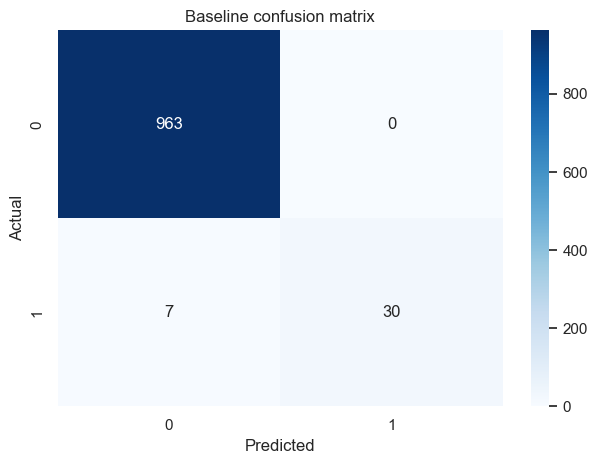

In [4]:
pred = baseline.predict(X_test)
print(classification_report(y_test, pred, zero_division=0))
cm = confusion_matrix(y_test, pred)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues")
plt.title("Baseline confusion matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

## 5. Class weights

`class_weight="balanced"` gives the minority class a larger weight in the loss. It is a cheap first
thing to try and does not change the training set.

In [5]:
balanced = ImbPipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=5000, class_weight="balanced", random_state=RANDOM_STATE)),
])
balanced.fit(X_train, y_train)
balanced_result = evaluate("Class weights", balanced, X_test, y_test)
{k: v for k, v in balanced_result.items() if k != "probabilities"}

{'model': 'Class weights',
 'accuracy': 0.943,
 'precision': 0.38095238095238093,
 'recall': 0.8648648648648649,
 'f1': 0.5289256198347108,
 'roc_auc': 0.9336813448962982,
 'pr_auc': 0.8607051769396451}

## 6. Resampling inside a pipeline

Putting the sampler inside an imbalanced-learn pipeline keeps it out of the validation folds during
cross-validation. Fitting SMOTE before splitting would leak synthetic information.

We compare random over-sampling, random under-sampling, and SMOTE.

In [6]:
resamplers = {
    "Random over-sampling": RandomOverSampler(random_state=RANDOM_STATE),
    "Random under-sampling": RandomUnderSampler(random_state=RANDOM_STATE),
    "SMOTE": SMOTE(random_state=RANDOM_STATE),
}

results = [baseline_result, balanced_result]
for name, sampler in resamplers.items():
    model = ImbPipeline([
        ("scaler", StandardScaler()),
        ("sampler", sampler),
        ("model", LogisticRegression(max_iter=5000, random_state=RANDOM_STATE)),
    ])
    model.fit(X_train, y_train)
    results.append(evaluate(name, model, X_test, y_test))

table = pd.DataFrame([{k: v for k, v in r.items() if k != "probabilities"} for r in results])
table.round(4).sort_values("pr_auc", ascending=False).reset_index(drop=True)

,model,accuracy,precision,recall,f1,roc_auc,pr_auc
0,Baseline,0.993,1.0000,0.8108,0.8955,0.9338,0.8635
1,Random under-sampling,0.936,0.3516,0.8649,0.5000,0.9351,0.8621
2,SMOTE,0.956,0.4507,0.8649,0.5926,0.9310,0.8618
3,Random over-sampling,0.943,0.3810,0.8649,0.5289,0.9358,0.8611
4,Class weights,0.943,0.3810,0.8649,0.5289,0.9337,0.8607


## 7. Precision-recall curves

PR curves show the trade-off at every threshold. A model can look similar on ROC-AUC but very
different on PR-AUC when the positive class is rare.

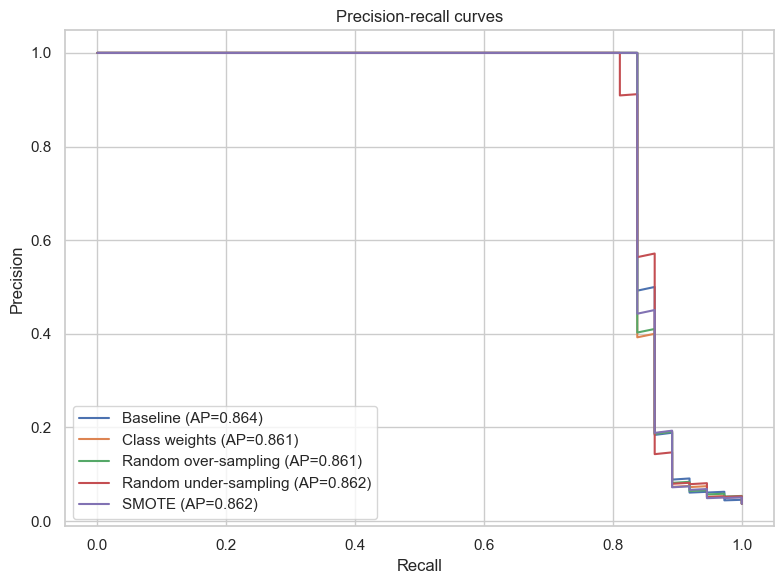

In [7]:
plt.figure(figsize=(8, 6))
for result in results:
    PrecisionRecallDisplay(
        precision=None, recall=None,
    )
    from sklearn.metrics import precision_recall_curve
    precision, recall, _ = precision_recall_curve(y_test, result["probabilities"])
    plt.plot(recall, precision, label=f"{result['model']} (AP={result['pr_auc']:.3f})")

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision-recall curves")
plt.legend(loc="best")
plt.tight_layout()
plt.show()

## 8. Threshold tuning

The default 0.5 threshold is arbitrary. If missing a positive is expensive, lower the threshold to
increase recall. The table below helps choose an operating point.

In [8]:
best_prob = balanced_result["probabilities"]
rows = []
for threshold in np.arange(0.05, 0.96, 0.05):
    pred = (best_prob >= threshold).astype(int)
    rows.append({
        "threshold": round(float(threshold), 2),
        "precision": precision_score(y_test, pred, zero_division=0),
        "recall": recall_score(y_test, pred, zero_division=0),
        "f1": f1_score(y_test, pred, zero_division=0),
    })
threshold_df = pd.DataFrame(rows)
threshold_df.round(3)

,threshold,precision,recall,f1
0,0.05,0.043,1.000,0.082
1,0.10,0.053,0.973,0.100
2,0.15,0.064,0.946,0.120
3,0.20,0.081,0.892,0.148
4,0.25,0.104,0.892,0.186
5,0.30,0.135,0.892,0.235
6,0.35,0.174,0.892,0.291
7,0.40,0.224,0.865,0.356
8,0.45,0.288,0.865,0.432
9,0.50,0.381,0.865,0.529


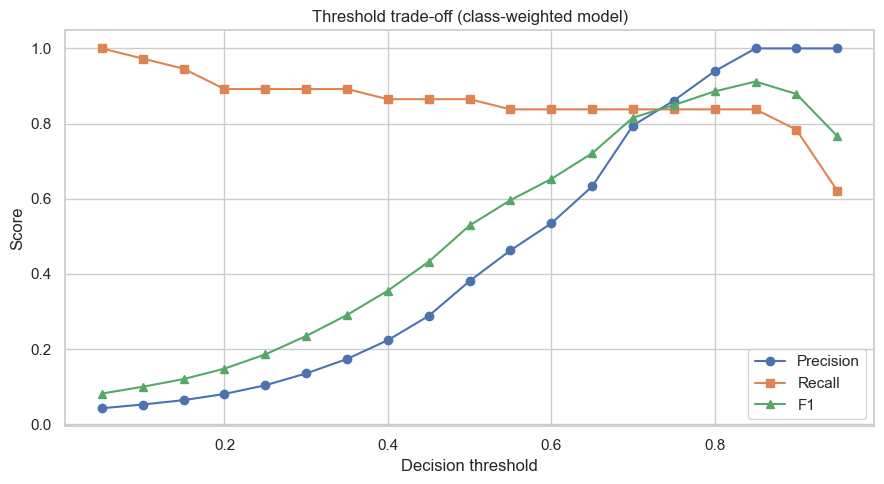

In [9]:
plt.figure(figsize=(9, 5))
plt.plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
plt.plot(threshold_df["threshold"], threshold_df["recall"], marker="s", label="Recall")
plt.plot(threshold_df["threshold"], threshold_df["f1"], marker="^", label="F1")
plt.xlabel("Decision threshold")
plt.ylabel("Score")
plt.title("Threshold trade-off (class-weighted model)")
plt.legend()
plt.tight_layout()
plt.show()

## 9. SMOTE caveats

- SMOTE interpolates in feature space; it can create unrealistic samples when features are categorical
  or when classes overlap heavily.
- It should be applied only to training data, never to validation or test data.
- Variants such as `SMOTEENN` and `SMOTETomek` combine over- and under-sampling.
- Resampling is not a substitute for better features, better labels, or a cost-sensitive objective.
- For extreme imbalance, anomaly-detection methods may be more appropriate than classification.

## Key takeaways

- Accuracy is not a useful headline metric for imbalanced data.
- Class weights are a strong, simple baseline.
- Resample inside a pipeline to avoid leakage.
- PR-AUC and recall are usually more informative than accuracy and ROC-AUC.
- Threshold tuning lets you choose an operating point without retraining.

## Exercises

1. Try `SMOTE(k_neighbors=3)` and `SMOTE(k_neighbors=10)`. How does PR-AUC change?
2. Combine SMOTE with random under-sampling using `SMOTEENN` or `SMOTETomek`.
3. Use `GridSearchCV` to tune the decision threshold and `C` jointly.
4. Compare a random forest with `class_weight="balanced_subsample"` to the resampled logistic model.
5. Explain why applying SMOTE before train/test splitting is a leakage bug.